In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

DIR_OUTPUT = "../output"

df = pd.read_csv('../data/cms_table5_dileptons.csv')


## Test plot

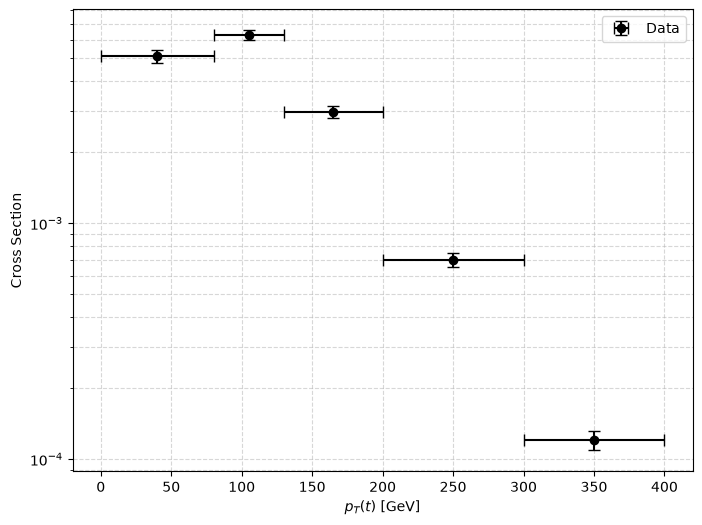

In [27]:
df_pT_t = df[df['variable'] == 'pT_t'].copy()
df_pT_tt = df[df['variable'] == 'pT_tt'].copy()
df_y_tt = df[df['variable'] == 'y_tt'].copy()
df_m_tt = df[df['variable'] == 'm_tt'].copy()

pT_t_eb_vals = df_pT_t['cross_section'].values
pT_t_eb_x = (df_pT_t['bin_min'] + df_pT_t['bin_max']) / 2
pT_t_eb_y_err = pT_t_eb_vals * (df_pT_t['total_err_pct'] / 100.0)
pT_t_eb_x_err = (df_pT_t["bin_max"] - df_pT_t["bin_min"]) / 2

plt.figure(figsize=(8, 6))

plt.errorbar(pT_t_eb_x, pT_t_eb_vals, xerr=pT_t_eb_x_err, yerr=pT_t_eb_y_err, fmt='o', color='black', capsize=4, label="Data")

plt.xlabel('$p_{T}(t)$ [GeV]')
plt.ylabel('Cross Section')
plt.yscale('log')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.savefig(f"{DIR_OUTPUT}/pT_t_dilepton.png", bbox_inches='tight')
plt.show()

## Batched production of all needed plots

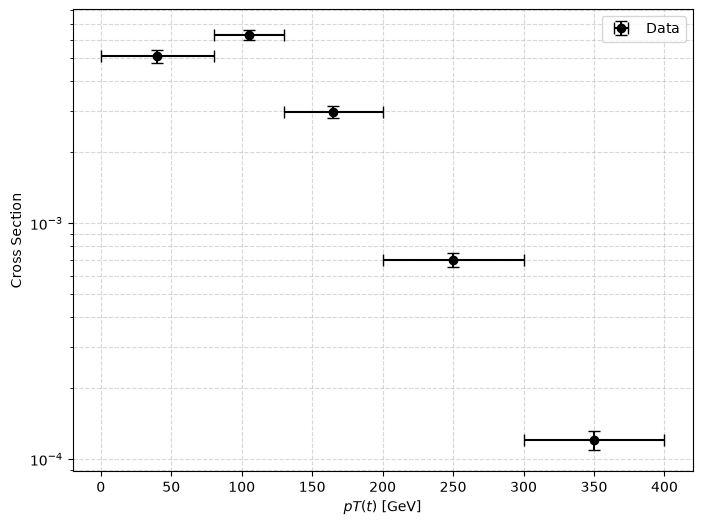

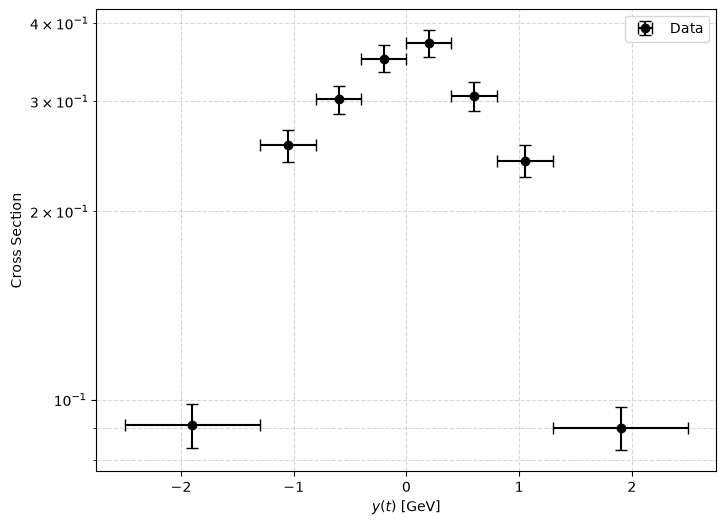

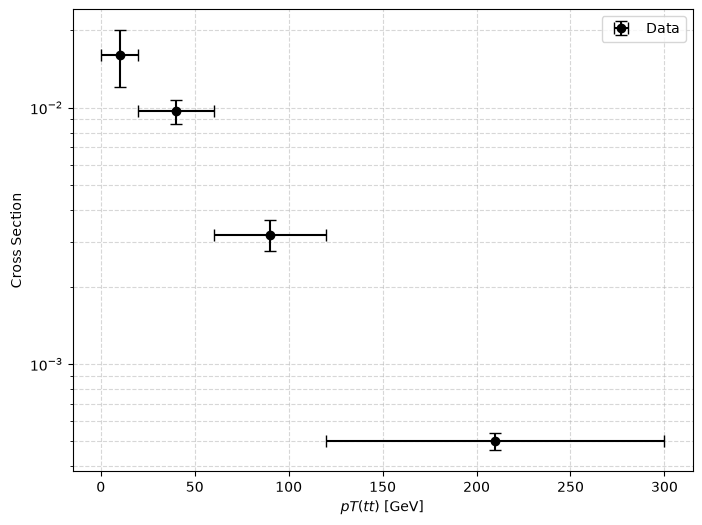

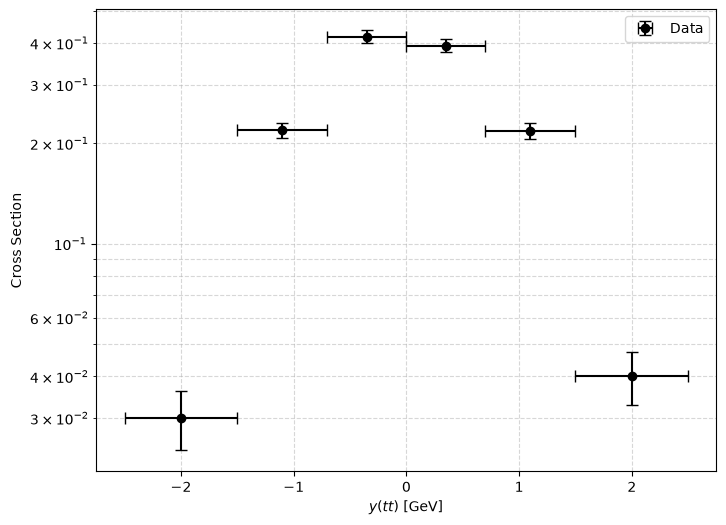

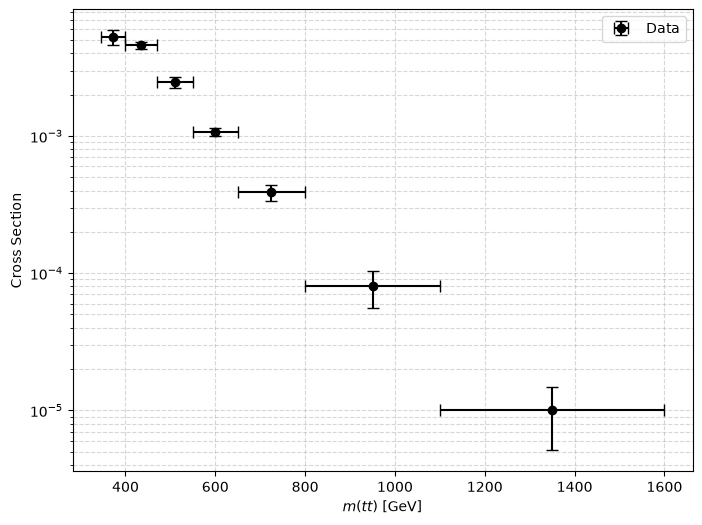

In [28]:
for i in ["pT_t", "y_t", "pT_tt", "y_tt", "m_tt"]:
    df_i = df[df['variable'] == f"{i}"].copy()

    i_eb_vals = df_i['cross_section'].values
    i_eb_x = (df_i['bin_min'] + df_i['bin_max']) / 2
    i_eb_y_err = i_eb_vals * (df_i['total_err_pct'] / 100.0)
    i_eb_x_err = (df_i["bin_max"] - df_i["bin_min"]) / 2

    plt.figure(figsize=(8, 6))

    plt.errorbar(i_eb_x, i_eb_vals, xerr=i_eb_x_err, yerr=i_eb_y_err, fmt='o', color='black', capsize=4, label="Data")

    plt.xlabel(f"${i.split('_')[0]}({i.split('_')[1]})$ [GeV]")
    plt.ylabel('Cross Section')
    plt.yscale('log')
    plt.legend()
    plt.grid(True, which="both", ls="--", alpha=0.5)

    plt.savefig(f"{DIR_OUTPUT}/{i}_dilepton_batched.png", bbox_inches='tight')
    plt.show()